<a href="https://colab.research.google.com/github/peter-adepoju/math-neuro-ml/blob/main/project/Project1_Starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MAMBA Project Week — Option 1: Choice from Visual Cortex**

**Question.** How well do neurons in mouse primary visual cortex (VISp) predict which way the mouse turns the wheel, and do neurons in other brain areas predict it better?

**Minimum result.** A decoder of choice from VISp counts in session 11, trained on half the turn trials and tested on the rest, with test accuracy and AUC and a bootstrap 95% interval for the AUC.

**Lessons to revisit.** 2 (projection), 5 (train/test), 8 and 12 (sigmoid, gradient descent), 15 (regularisation), 20 (ROC, bootstrap).

**Data.** `steinmetz_s11_lederberg.npz` (and `steinmetz_s25_radnitz.npz` for the stretch goal). Steinmetz et al. (2019), *Nature* 576:266–273; subsets of the Neuromatch Academy release; the original data are released under CC0.

**How to use this notebook.** Run it top to bottom: it loads the data, shows it, and works one first step for you. Cells marked `# TODO` are yours; each is followed by a check cell that prints *TODO* until your code sets the variables it names, then tests their shapes and simple sanity conditions. Add your own cells freely, but keep every array described by its shape and units.

### Set-up

In [1]:
# SETUP -- run first.
import os, urllib.request
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
PALETTE = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']   # Okabe-Ito, as in the lessons
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': False, 'figure.dpi': 100})
DATA_URL = 'https://raw.githubusercontent.com/peter-adepoju/math-neuro-ml/51d88220064023b5d3240c39e19b07acc7896f44/data/'

def load(name):
    # A local copy (here, or in the repository's data/ folder) first; otherwise download it from the pinned commit.
    for candidate in [name, os.path.join('..', 'data', name), os.path.join('..', '..', 'data', name)]:
        if os.path.exists(candidate):
            return np.load(candidate)
    urllib.request.urlretrieve(DATA_URL + name, name)
    return np.load(name)

def todo(*values):
    # True while any of the values is still None: the check cells below use it to wait for your code.
    return any(v is None for v in values)
print('Set-up complete.')

Set-up complete.


### Data tour

| Array | Shape | Meaning, units |
|---|---|---|
| `counts` | (340, 698) | (trial, neuron): spikes 50–250 ms after stimulus onset |
| `area` | (698,) | brain area of each neuron (Allen acronym; `root` = not assigned) |
| `response` | (340,) | wheel turn: +1 left, −1 right, 0 no turn |
| `c_left`, `c_right` | (340,) | contrast on each side: 0, 0.25, 0.5 or 1 |

We keep the **turn trials** only (response ±1): on no-turn trials there is no choice to decode.

turn trials: 276  left turns: 135  right turns: 141
areas with >= 20 neurons: {'CA1': 50, 'DG': 65, 'MD': 126, 'PL': 56, 'SUB': 105, 'VISam': 79, 'VISp': 66, 'root': 100}


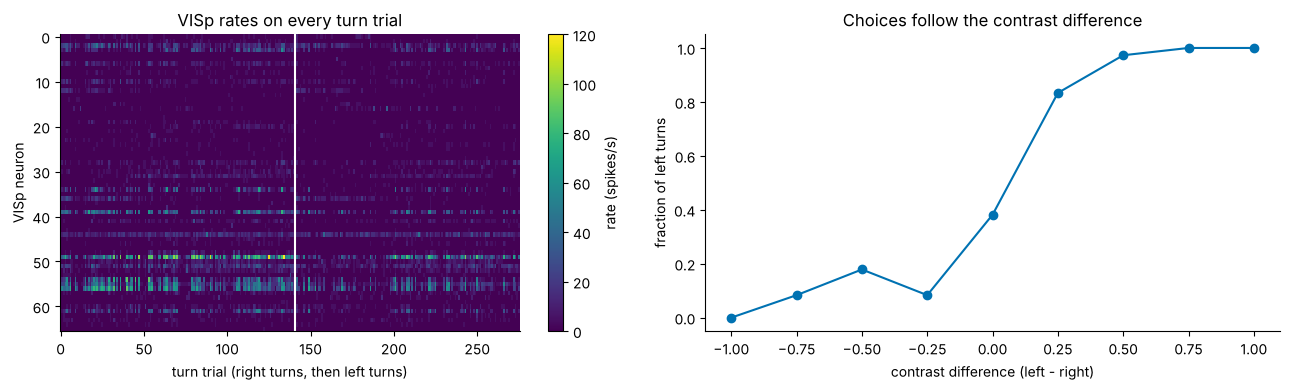

In [2]:
d = load('steinmetz_s11_lederberg.npz')
counts, area = d['counts'].astype(float), d['brain_area']
response, c_left, c_right = d['response'], d['contrast_left'], d['contrast_right']
turn = response != 0
X_all = counts[turn]                                   # (276, 698) spikes per 200 ms, turn trials only
y = (response[turn] == 1).astype(int)                  # (276,) 1 = left turn, 0 = right turn
diff = (c_left - c_right)[turn]                        # (276,) contrast difference, left minus right
print("turn trials:", X_all.shape[0], " left turns:", y.sum(), " right turns:", (1 - y).sum())
names, n_per = np.unique(area, return_counts=True)
print("areas with >= 20 neurons:", {str(a): int(k) for a, k in zip(names, n_per) if k >= 20})

vis = area == 'VISp'
order = np.argsort(y, kind='stable')
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
im = axes[0].imshow(X_all[order][:, vis].T / 0.2, aspect='auto', cmap='viridis', interpolation='nearest')
axes[0].axvline((1 - y).sum() - 0.5, color='white', lw=1.5)
axes[0].set_xlabel('turn trial (right turns, then left turns)'); axes[0].set_ylabel('VISp neuron'); axes[0].set_title('VISp rates on every turn trial')
plt.colorbar(im, ax=axes[0], label='rate (spikes/s)')
levels = np.unique(diff)
axes[1].plot(levels, [y[diff == v].mean() for v in levels], 'o-', color=PALETTE[0])
axes[1].set_xlabel('contrast difference (left - right)'); axes[1].set_ylabel('fraction of left turns'); axes[1].set_title('Choices follow the contrast difference')
plt.tight_layout(); plt.show()

### Worked first step: a projection decoder for VISp

Split the turn trials at random into halves (training, test). On the training half, the decoder direction is the difference of the mean VISp population vectors for left and right turns; a trial is called "left" when its projection on that direction lies above the midpoint of the two class means (Lesson 2).

In [3]:
perm = rng.permutation(len(y))
train, test = np.zeros(len(y), bool), np.zeros(len(y), bool)
train[perm[: len(y) // 2]] = True; test[perm[len(y) // 2:]] = True
Xv = X_all[:, vis]                                                     # (276, 66) VISp counts
mu_L, mu_R = Xv[train & (y == 1)].mean(axis=0), Xv[train & (y == 0)].mean(axis=0)   # (66,) each
w_proj = mu_L - mu_R                                                   # (66,) decoder direction, spikes
cut = w_proj @ (mu_L + mu_R) / 2                                       # midpoint threshold
pred = (Xv[test] @ w_proj > cut).astype(int)
print(f"projection decoder, VISp: test accuracy {np.mean(pred == y[test]):.3f}  (always guessing the larger class: {max(y[test].mean(), 1 - y[test].mean()):.3f})")

projection decoder, VISp: test accuracy 0.703  (always guessing the larger class: 0.522)


In [4]:
# TODO 1 -- Logistic decoder by gradient descent (Lessons 8, 12, 15).
# Standardise the VISp counts with TRAINING means and SDs (drop neurons with SD 0 in training). Fit
#   p(left) = sigmoid(b + Z @ w)
# by gradient descent on the mean negative log-likelihood plus (lam / 2) * |w|^2, with lam = 1.0.
# Store the weights in w_log (n_kept,), the bias in b_log, the test-trial scores Z_test @ w_log + b_log in score_test,
# and the test accuracy (score > 0 means "left") in acc_log.
w_log = b_log = score_test = acc_log = None

In [5]:
if todo(w_log, b_log, score_test, acc_log):
    print('TODO 1 not done yet.')
else:
    assert np.shape(score_test) == (test.sum(),), "one score per test trial"
    assert 0 <= acc_log <= 1
    print('Check 1 passed.')

TODO 1 not done yet.


In [6]:
# TODO 2 -- AUC with a bootstrap interval (Lesson 20).
# Write auc(scores, labels): the probability that a random left-turn trial scores higher than a random right-turn
# trial (ties count 1/2). Compute auc_visp on the test trials, then resample the test trials with replacement 2000
# times (use rng) and store the 2.5th and 97.5th percentiles of the resampled AUCs in ci_visp (shape (2,)).
def auc(scores, labels):
    return None
auc_visp = ci_visp = None

In [7]:
if todo(auc_visp, ci_visp):
    print('TODO 2 not done yet.')
else:
    assert abs(auc(np.array([1., 2., 3.]), np.array([0, 1, 1])) - 1.0) < 1e-12, "a perfect ranking has AUC 1"
    assert ci_visp[0] <= auc_visp <= ci_visp[1] + 1e-9
    print('Check 2 passed.')

TODO 2 not done yet.


In [8]:
# TODO 3 -- Every area with at least 20 neurons.
# Repeat TODO 1 and TODO 2 for each such area (same train/test split). Store a dict area_auc = {area: (auc, low, high)}
# and plot the AUCs with their intervals, sorted, with a line at 0.5 (chance).
area_auc = None

In [9]:
if todo(area_auc):
    print('TODO 3 not done yet.')
else:
    assert 'VISp' in area_auc and all(len(v) == 3 for v in area_auc.values())
    print('Check 3 passed.')

TODO 3 not done yet.


### Before the talk
- Report chance level for your class balance, and AUC alongside accuracy.
- The test half is small (about 140 trials): show intervals, not just point estimates.
- Choice and stimulus are correlated: an area that "predicts choice" may be encoding the stimulus. The stretch goal (error trials) separates them.
- Stretch: repeat in `steinmetz_s25_radnitz.npz` (162 VISp neurons).